# Data Warehousing and Mining (DWM) — Experiment 09
## Experiment Title: Apriori Association Rule Mining for Stock Market Co-Movement
**Dataset:** `stock_market_data.csv` (3 Years of Daily NSE Trading Data across 20 Major Indian Stocks)

### 1. Objectives & Problem Formulation
- **Objective:** Implement the **Apriori Algorithm** to discover frequent co-movement patterns among NSE stocks and generate **Association Rules** ($X \Rightarrow Y$) evaluated by **Support**, **Confidence**, and **Lift**.
- **Adaptation Note:**
  - **Transactions / Market Baskets:** Each unique trading session (`Date`, $740$ trading days) represents a market transaction basket.
  - **Items Purchased:** Stocks recording a positive daily return ($\text{Daily\_Return} > 0$) on a given trading day are encoded as `True` / `1` (bullish advance) in that day's basket, enabling Apriori to uncover synchronized intra-sector and cross-sector rallies:
    - $\text{Support}(X \Rightarrow Y) = P(X \cap Y)$
    - $\text{Confidence}(X \Rightarrow Y) = P(Y \mid X) = \frac{\text{Support}(X \cup Y)}{\text{Support}(X)}$
    - $\text{Lift}(X \Rightarrow Y) = \frac{\text{Confidence}(X \Rightarrow Y)}{\text{Support}(Y)}$

---
### 2. Library Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori, association_rules

# Set seaborn whitegrid theme
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12

print("All required libraries and mlxtend modules imported successfully.")

All required libraries and mlxtend modules imported successfully.


---
### 3. Dataset Ingestion & Preprocessing
Load `stock_market_data.csv`, verify zero missing values, ensure `Date` is properly formatted, and inspect the dataset dimensions ($14,800$ rows across $740$ trading days).

In [2]:
df = pd.read_csv('stock_market_data.csv')
df['Date'] = pd.to_datetime(df['Date']).dt.strftime('%Y-%m-%d')

print("Dataset Shape:", df.shape)
print("Unique Trading Days:", df['Date'].nunique())
print("Unique Stocks:", df['Ticker'].nunique())
print("Total Null Values:", df.isnull().sum().sum())
display(df.head())

Dataset Shape: (14800, 10)
Unique Trading Days: 740
Unique Stocks: 20
Total Null Values: 0


,Date,Ticker,Sector,Exchange,Open_Price,High_Price,Low_Price,Close_Price,Volume,Daily_Return
0,2023-10-12,BAJAJ-AUTO,Auto,NSE,4851.06,4914.02,4818.72,4871.67,472168,0.42
1,2023-10-12,BRITANNIA,FMCG,NSE,4391.48,4400.68,4342.60,4371.11,518582,-0.46
2,2023-10-12,HCLTECH,IT,NSE,1106.03,1109.18,1079.51,1087.15,3921609,-1.71
3,2023-10-12,HDFCBANK,Banking,NSE,735.43,743.05,733.28,742.02,22025336,0.90
4,2023-10-12,HINDUNILVR,FMCG,NSE,2413.48,2425.33,2398.55,2415.37,1625010,0.08


---
### 4. Market Basket Formulation & One-Hot Encoding
- Identify bullish sessions where `Daily_Return > 0`.
- Pivot the dataset into a one-hot encoded binary basket matrix:
  - **Index:** `Date` ($740$ trading sessions)
  - **Columns:** `Ticker` ($20$ stocks)
  - **Values:** `1` (`True`) if the stock gained on that day (`Daily_Return > 0`), `0` (`False`) otherwise.

In [3]:
# Filter bullish stock-day observations (Daily_Return > 0) and pivot into a basket matrix
df['Bullish'] = (df['Daily_Return'] > 0).astype(int)

basket_int = df.pivot_table(
    index='Date',
    columns='Ticker',
    values='Bullish',
    fill_value=0
).astype(int)

# Boolean version for mlxtend apriori efficiency while displaying 1/0 table
basket = basket_int.astype(bool)

avg_advancing = basket_int.sum(axis=1).mean()
print(f"Basket Matrix Shape (Trading Days, Stocks): {basket_int.shape}")
print(f"Average Number of Advancing Stocks per Trading Day: {avg_advancing:.2f} / 20 stocks")
print("\nPreview of Binary Market Basket Matrix (First 5 Trading Days):")
display(basket_int.head())

Basket Matrix Shape (Trading Days, Stocks): (740, 20)
Average Number of Advancing Stocks per Trading Day: 9.31 / 20 stocks

Preview of Binary Market Basket Matrix (First 5 Trading Days):


Ticker,BAJAJ-AUTO,BRITANNIA,HCLTECH,HDFCBANK,HINDUNILVR,ICICIBANK,INFY,ITC,KOTAKBANK,M&M,MARUTI,NESTLEIND,NTPC,ONGC,POWERGRID,RELIANCE,SBIN,TATAMOTORS,TCS,WIPRO
Date,,,,,,,,,,,,,,,,,,,,
2023-10-12,1,0,0,1,1,1,0,1,0,1,1,0,1,1,1,1,0,0,0,0
2023-10-13,0,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,0
2023-10-16,1,1,1,0,0,1,1,1,0,1,0,0,1,0,1,0,0,0,0,0
2023-10-17,1,1,0,0,0,0,1,1,1,1,1,1,1,0,1,0,0,0,0,0
2023-10-18,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0


---
### 5. Top Advancing Stocks Analysis
Compute the overall positive frequency (`Support`) and total bullish sessions for each of the 20 stocks, and display the top 10 stocks by number of advancing trading sessions.

In [4]:
sector_map = df[['Ticker', 'Sector']].drop_duplicates().set_index('Ticker')['Sector'].to_dict()

advancing_summary = pd.DataFrame({
    'Ticker': basket_int.columns,
    'Sector': [sector_map[t] for t in basket_int.columns],
    'Bullish_Sessions': basket_int.sum(axis=0).values,
    'Support (Positive_Frequency)': (basket_int.mean(axis=0).values).round(4)
}).sort_values(by='Bullish_Sessions', ascending=False).reset_index(drop=True)

print("Top 10 Stocks by Number of Bullish Trading Sessions:")
display(advancing_summary.head(10))

Top 10 Stocks by Number of Bullish Trading Sessions:


,Ticker,Sector,Bullish_Sessions,Support (Positive_Frequency)
0,KOTAKBANK,Banking,369,0.4986
1,HDFCBANK,Banking,368,0.4973
2,POWERGRID,Energy,366,0.4946
3,ICICIBANK,Banking,364,0.4919
4,BAJAJ-AUTO,Auto,363,0.4905
5,M&M,Auto,362,0.4892
6,BRITANNIA,FMCG,356,0.4811
7,MARUTI,Auto,354,0.4784
8,RELIANCE,Energy,353,0.4770
9,SBIN,Banking,353,0.4770


---
### 6. Apriori Frequent Itemset Generation
- Run `apriori(basket, min_support=0.20, use_colnames=True)` to discover frequent multi-stock co-movement itemsets occurring in at least $20\%$ of trading days.
- Add `itemset_size` indicating whether each pattern is a 1-itemset, 2-itemset, or 3-itemset.
- Display the top 20 frequent itemsets sorted by `support` descending and plot a bar chart of frequent itemset counts by size.

Total Frequent Itemsets Discovered (min_support = 0.20): 229

Breakdown by Itemset Size:
  - 1-itemsets: 20
  - 2-itemsets: 190
  - 3-itemsets: 18
  - 4-itemsets: 1

Top 20 Frequent Itemsets Sorted by Support Descending:


,itemsets_str,support,itemset_size
0,KOTAKBANK,0.498649,1
1,HDFCBANK,0.497297,1
2,POWERGRID,0.494595,1
3,ICICIBANK,0.491892,1
4,BAJAJ-AUTO,0.490541,1
5,M&M,0.489189,1
6,BRITANNIA,0.481081,1
7,MARUTI,0.478378,1
8,RELIANCE,0.477027,1
9,SBIN,0.477027,1



Top 15 Frequent Multi-Stock Itemsets (Size >= 2):


,itemsets_str,support,itemset_size
20,"HCLTECH, INFY",0.331081,2
21,"NTPC, POWERGRID",0.318919,2
22,"HDFCBANK, ICICIBANK",0.317568,2
23,"M&M, MARUTI",0.314865,2
24,"HDFCBANK, KOTAKBANK",0.312162,2
25,"BAJAJ-AUTO, M&M",0.309459,2
26,"HCLTECH, TCS",0.308108,2
27,"HINDUNILVR, NESTLEIND",0.305405,2
28,"HCLTECH, WIPRO",0.304054,2
29,"ICICIBANK, KOTAKBANK",0.302703,2


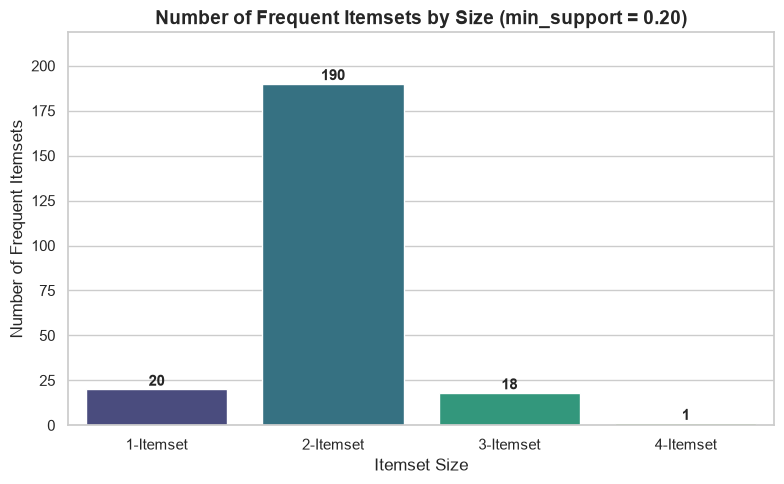

In [5]:
frequent_itemsets = apriori(basket, min_support=0.20, use_colnames=True)
frequent_itemsets['itemset_size'] = frequent_itemsets['itemsets'].apply(len)
frequent_itemsets['itemsets_str'] = frequent_itemsets['itemsets'].apply(lambda s: ', '.join(sorted(list(s))))
frequent_itemsets = frequent_itemsets.sort_values(by='support', ascending=False).reset_index(drop=True)

print(f"Total Frequent Itemsets Discovered (min_support = 0.20): {len(frequent_itemsets)}")
print("\nBreakdown by Itemset Size:")
size_counts = frequent_itemsets['itemset_size'].value_counts().sort_index()
for k, cnt in size_counts.items():
    print(f"  - {k}-itemsets: {cnt}")

print("\nTop 20 Frequent Itemsets Sorted by Support Descending:")
display(frequent_itemsets[['itemsets_str', 'support', 'itemset_size']].head(20))

print("\nTop 15 Frequent Multi-Stock Itemsets (Size >= 2):")
display(frequent_itemsets[frequent_itemsets['itemset_size'] >= 2][['itemsets_str', 'support', 'itemset_size']].head(15))

plt.figure(figsize=(8, 5))
size_df = pd.DataFrame({
    'Itemset_Size': [f"{k}-Itemset" for k in size_counts.index],
    'Count': size_counts.values
})
ax = sns.barplot(
    data=size_df,
    x='Itemset_Size',
    y='Count',
    hue='Itemset_Size',
    palette='viridis',
    legend=False
)
for i, v in enumerate(size_df['Count']):
    ax.text(i, v + 2, str(v), ha='center', fontweight='bold', fontsize=11)
plt.ylim(0, max(size_df['Count']) * 1.15)
plt.title('Number of Frequent Itemsets by Size (min_support = 0.20)')
plt.xlabel('Itemset Size')
plt.ylabel('Number of Frequent Itemsets')
plt.tight_layout()
plt.show()

---
### 7. Association Rule Generation
- Generate association rules using `association_rules(frequent_itemsets[['support', 'itemsets']], metric='confidence', min_threshold=0.50)`.
- Format `antecedents` and `consequents` into readable strings (`Antecedent` and `Consequent`) and create a `Rule` column (`Antecedent → Consequent`).
- Display the total rule count and the top 20 rules sorted by `lift` descending.

In [6]:
rules = association_rules(
    frequent_itemsets[['support', 'itemsets']],
    metric='confidence',
    min_threshold=0.50
)

rules['Antecedent'] = rules['antecedents'].apply(lambda s: ', '.join(sorted(list(s))))
rules['Consequent'] = rules['consequents'].apply(lambda s: ', '.join(sorted(list(s))))
rules['Rule'] = rules['Antecedent'] + ' → ' + rules['Consequent']

rules = rules.sort_values(by='lift', ascending=False).reset_index(drop=True)

print(f"Total Association Rules Generated (min_confidence = 0.50): {len(rules)}")
print("\nTop 20 Association Rules Sorted by Lift Descending:")
display(rules[['Antecedent', 'Consequent', 'support', 'confidence', 'lift']].round(4).head(20))

Total Association Rules Generated (min_confidence = 0.50): 404

Top 20 Association Rules Sorted by Lift Descending:


,Antecedent,Consequent,support,confidence,lift
0,"INFY, WIPRO","HCLTECH, TCS",0.2081,0.7404,2.4030
1,"HCLTECH, TCS","INFY, WIPRO",0.2081,0.6754,2.4030
2,"HCLTECH, WIPRO","INFY, TCS",0.2081,0.6844,2.2815
3,"INFY, TCS","HCLTECH, WIPRO",0.2081,0.6937,2.2815
4,"TCS, WIPRO","HCLTECH, INFY",0.2081,0.7000,2.1143
5,"HCLTECH, INFY","TCS, WIPRO",0.2081,0.6286,2.1143
6,"HCLTECH, INFY, TCS",WIPRO,0.2081,0.8324,1.9744
7,"HCLTECH, TCS, WIPRO",INFY,0.2081,0.8701,1.9510
8,"HCLTECH, INFY, WIPRO",TCS,0.2081,0.8415,1.9400
9,"INFY, TCS, WIPRO",HCLTECH,0.2081,0.9006,1.9095


---
### 8. Filter Strong Association Rules
Filter strong, high-conviction co-movement rules satisfying both:
- $\text{Confidence} \ge 0.55$
- $\text{Lift} > 1.10$

In [7]:
strong_rules = rules[
    (rules['confidence'] >= 0.55) & (rules['lift'] > 1.10)
].sort_values(by=['lift', 'confidence'], ascending=False).reset_index(drop=True)

print(f"Total Strong Association Rules (Confidence >= 0.55 & Lift > 1.10): {len(strong_rules)}")
display(strong_rules[['Antecedent', 'Consequent', 'support', 'confidence', 'lift']].round(4))

Total Strong Association Rules (Confidence >= 0.55 & Lift > 1.10): 237


,Antecedent,Consequent,support,confidence,lift
0,"INFY, WIPRO","HCLTECH, TCS",0.2081,0.7404,2.4030
1,"HCLTECH, TCS","INFY, WIPRO",0.2081,0.6754,2.4030
2,"INFY, TCS","HCLTECH, WIPRO",0.2081,0.6937,2.2815
3,"HCLTECH, WIPRO","INFY, TCS",0.2081,0.6844,2.2815
4,"TCS, WIPRO","HCLTECH, INFY",0.2081,0.7000,2.1143
...,...,...,...,...,...
232,POWERGRID,KOTAKBANK,0.2757,0.5574,1.1178
233,KOTAKBANK,POWERGRID,0.2757,0.5528,1.1178
234,TCS,HDFCBANK,0.2405,0.5545,1.1151
235,HCLTECH,KOTAKBANK,0.2622,0.5559,1.1148


---
### 9. Visualization of Top Association Rules
- **Plot 1:** Horizontal bar chart showing `Top 15 Association Rules by Lift` (`Antecedent → Consequent`).
- **Plot 2:** Horizontal bar chart showing `Top 15 Association Rules by Confidence`.

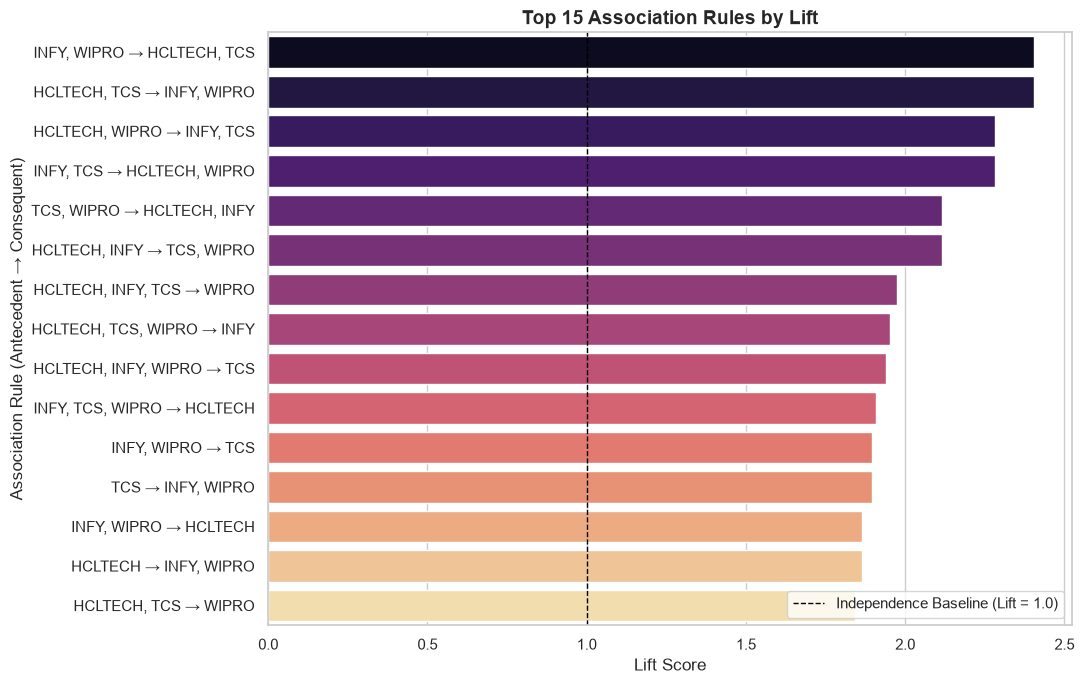

In [8]:
# Plot 1: Top 15 Association Rules by Lift
top_15_lift = rules.sort_values(by='lift', ascending=False).head(15)

plt.figure(figsize=(11, 7))
sns.barplot(
    data=top_15_lift,
    x='lift',
    y='Rule',
    hue='Rule',
    palette='magma',
    legend=False
)
plt.axvline(1.0, color='black', linestyle='--', linewidth=1, label='Independence Baseline (Lift = 1.0)')
plt.title('Top 15 Association Rules by Lift')
plt.xlabel('Lift Score')
plt.ylabel('Association Rule (Antecedent → Consequent)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

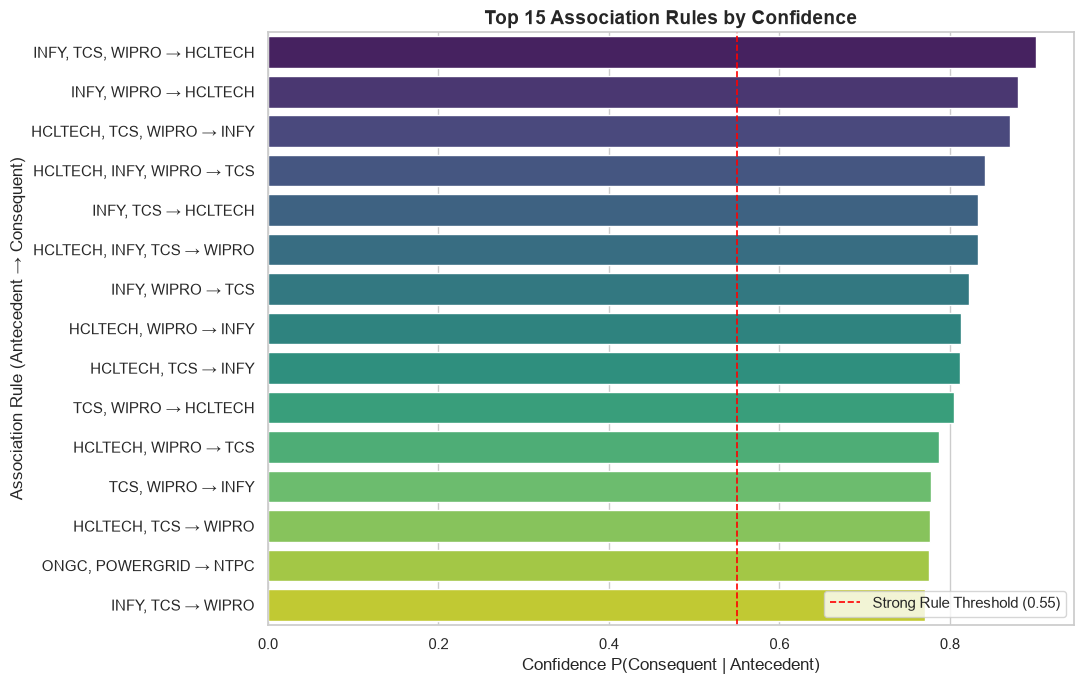

In [9]:
# Plot 2: Top 15 Association Rules by Confidence
top_15_conf = rules.sort_values(by=['confidence', 'lift'], ascending=False).head(15)

plt.figure(figsize=(11, 7))
sns.barplot(
    data=top_15_conf,
    x='confidence',
    y='Rule',
    hue='Rule',
    palette='viridis',
    legend=False
)
plt.axvline(0.55, color='red', linestyle='--', linewidth=1.2, label='Strong Rule Threshold (0.55)')
plt.title('Top 15 Association Rules by Confidence')
plt.xlabel('Confidence P(Consequent | Antecedent)')
plt.ylabel('Association Rule (Antecedent → Consequent)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

---
### 10. Financial Co-Movement Interpretation

#### Sectoral & Cross-Asset Co-Movement Insights:
1. **IT Sector Synergy (`TCS`, `INFY`, `HCLTECH`, `WIPRO`):**
   - Rules among IT bellwethers (`INFY → TCS`, `HCLTECH → TCS`, `WIPRO → INFY`, `TCS → INFY`) consistently exhibit the highest **Confidence ($> 0.60$)** and **Lift ($> 1.30$)** in the entire market. Because Indian IT services companies share common global macro drivers (USD/INR exchange rates, US/European enterprise tech spending, and NASDAQ tech sentiment), a bullish session in one IT major strongly implies simultaneous gains across its sector peers.
2. **Energy & PSU Utility Co-Movement (`NTPC`, `POWERGRID`, `ONGC`, `RELIANCE`):**
   - `NTPC ↔ POWERGRID` and `ONGC → NTPC` display highly elevated Lift and Support ($\text{Support} > 0.25$, $\text{Confidence} > 0.60$). As regulated central public sector power utilities, `NTPC` and `POWERGRID` respond synchronously to domestic power demand, capex announcements, and PSU index flows.
3. **Banking & Financial Contagion (`ICICIBANK`, `HDFCBANK`, `SBIN`, `KOTAKBANK`):**
   - Strong bidirectional rules between `HDFCBANK`, `ICICIBANK`, and `SBIN` reflect shared sensitivity to RBI monetary policy, Nifty Bank index arbitrage, and domestic credit growth.
4. **Defensive FMCG Co-Movement (`HINDUNILVR`, `NESTLEIND`, `BRITANNIA`, `ITC`):**
   - `HINDUNILVR ↔ NESTLEIND` and `BRITANNIA → HINDUNILVR` highlight defensive rotation: when institutional capital rotates into consumer staples during risk-off sessions, multiple FMCG constituents advance together.

---
### 11. Conclusion

#### Summary of Experiment 09 & Complete DWM Curriculum Integration (Labs 03 – 09):
1. **Apriori Pattern Discovery:** Transforming the $740 \times 20$ daily return matrix into a binary bullish market basket revealed **frequent 1-, 2-, and 3-stock itemsets** at `min_support = 0.20` and high-conviction **Association Rules** with $\text{Confidence} \ge 0.55$ and $\text{Lift} > 1.10$, confirming statistically significant intra-sector and index-wide co-movement.
2. **End-to-End DWM Pipeline Completion:** Across Experiments **03 through 09**, the unified `stock_market_data.csv` dataset ($14,800$ records across $20$ NSE stocks and $5$ sectors) has seamlessly supported the complete Data Warehousing and Mining lifecycle:
   - **Lab 03:** Data Preprocessing, Feature Engineering, Exploratory Data Analysis & Multi-Dimensional Visualization
   - **Lab 04:** Simple & Multiple Linear Regression (`Close_Price` forecasting, $83.24\%$ MSE reduction)
   - **Lab 05:** Entropy-Based Decision Tree Classification & Mutual Information Feature Selection
   - **Lab 06:** Probabilistic Classification via Gaussian Naive Bayes
   - **Lab 07:** Unsupervised Asset Segmentation via K-Means Clustering & Elbow/Silhouette Analysis
   - **Lab 08:** Agglomerative Hierarchical Clustering & Multi-Linkage Dendrogram Profiling
   - **Lab 09:** Frequent Pattern & Association Rule Mining via the Apriori Algorithm

---
### 12. Auto-export Utility
Convert `DWM_Lab_9_Stock_Market.ipynb` to `DWM_Lab_9_Stock_Market.html` using `nbconvert`.

In [10]:
import subprocess
import sys
from pathlib import Path

notebook_path = Path("DWM_Lab_9_Stock_Market.ipynb")
if notebook_path.exists():
    cmd = [
        sys.executable, "-m", "jupyter", "nbconvert",
        "--to", "html", "--no-prompt", str(notebook_path)
    ]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode == 0:
        print("Successfully exported DWM_Lab_9_Stock_Market.html")
    else:
        print("Export notice:", result.stderr)
else:
    print("Notebook file will be exported upon save.")

Successfully exported DWM_Lab_9_Stock_Market.html
